In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout


In [ ]:
from google.colab import files
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

data = pd.read_csv(
    file_name,
    sep=",",
    header=0
)

print(data.head())
print(data.columns)
print("Total data:", len(data))


Saving ethreum.csv.csv to ethreum.csv.csv
                     Open time    Open    High     Low   Close    Volume  \
0  2017-08-17 04:00:00.000000   301.13  301.13  298.00  298.00   5.80167   
1  2017-08-17 04:15:00.000000   298.00  300.80  298.00  299.39  31.44065   
2  2017-08-17 04:30:00.000000   299.39  300.79  299.39  299.60  52.93579   
3  2017-08-17 04:45:00.000000   299.60  302.57  299.60  301.61  35.49066   
4  2017-08-17 05:00:00.000000   301.61  302.57  300.95  302.01  81.69235   

                    Close time  Quote asset volume  Number of trades  \
0  2017-08-17 04:14:59.999000          1744.766104                22   
1  2017-08-17 04:29:59.999000          9396.917813                26   
2  2017-08-17 04:44:59.999000         15851.075415                39   
3  2017-08-17 04:59:59.999000         10692.044849                42   
4  2017-08-17 05:14:59.999000         24620.724757                52   

   Taker buy base asset volume  Taker buy quote asset volume  Ignore

In [ ]:
df = data.copy()

df.columns = df.columns.str.lower().str.replace(" ", "_")

df['open_time'] = pd.to_datetime(df['open_time'], errors='coerce')

df = df.dropna(subset=['open_time'])

df.set_index('open_time', inplace=True)

df = df.sort_index()

close_price = df[['close']]

print("Jumlah data setelah cleaning:", len(close_price))
close_price.head()

Jumlah data setelah cleaning: 295865


,close
open_time,
2017-08-17 04:00:00,298.00
2017-08-17 04:15:00,299.39
2017-08-17 04:30:00,299.60
2017-08-17 04:45:00,301.61
2017-08-17 05:00:00,302.01


In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(close_price)


In [ ]:
def create_dataset(dataset, window_size):
    X, y = [], []
    for i in range(window_size, len(dataset)):
        X.append(dataset[i-window_size:i, 0])
        y.append(dataset[i, 0])
    return np.array(X), np.array(y)

window_size = 60
X, y = create_dataset(scaled_data, window_size)

X = np.reshape(X, (X.shape[0], X.shape[1], 1))


In [ ]:
train_size = int(len(X) * 0.8)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]


In [ ]:
model = Sequential()
model.add(LSTM(64, return_sequences=True, input_shape=(window_size, 1)))
model.add(Dropout(0.2))

model.add(LSTM(64))
model.add(Dropout(0.2))

model.add(Dense(1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,985 (195.25 KB)

 Trainable params: 49,985 (195.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test)
)


Epoch 1/20
7396/7396 ━━━━━━━━━━━━━━━━━━━━ 515s 69ms/step - loss: 0.0012 - val_loss: 5.1621e-05
Epoch 2/20
7396/7396 ━━━━━━━━━━━━━━━━━━━━ 570s 70ms/step - loss: 3.3278e-04 - val_loss: 2.1734e-05
Epoch 3/20
7396/7396 ━━━━━━━━━━━━━━━━━━━━ 545s 74ms/step - loss: 3.1308e-04 - val_loss: 3.6549e-04
Epoch 4/20
7396/7396 ━━━━━━━━━━━━━━━━━━━━ 515s 70ms/step - loss: 3.0514e-04 - val_loss: 2.9978e-05
Epoch 5/20
7396/7396 ━━━━━━━━━━━━━━━━━━━━ 558s 69ms/step - loss: 2.9337e-04 - val_loss: 2.4883e-05
Epoch 6/20
7396/7396 ━━━━━━━━━━━━━━━━━━━━ 512s 69ms/step - loss: 2.9279e-04 - val_loss: 7.2730e-05
Epoch 7/20
7396/7396 ━━━━━━━━━━━━━━━━━━━━ 510s 69ms/step - loss: 2.8672e-04 - val_loss: 1.7772e-04
Epoch 8/20
7396/7396 ━━━━━━━━━━━━━━━━━━━━ 564s 76ms/step - loss: 2.8438e-04 - val_loss: 5.8510e-05
Epoch 9/20
7396/7396 ━━━━━━━━━━━━━━━━━━━━ 534s 72ms/step - loss: 2.8390e-04 - val_loss: 3.6934e-05
Epoch 10/20
7396/7396 ━━━━━━━━━━━━━━━━━━━━ 509s 69ms/step - loss: 2.8079e-04 - val_loss: 7.6093e-05
Epoch 11/20
7

In [ ]:
predicted_price = model.predict(X_test)

# Kembalikan ke skala asli
predicted_price = scaler.inverse_transform(predicted_price)
actual_price = scaler.inverse_transform(y_test.reshape(-1, 1))

# Evaluasi dasar
rmse = np.sqrt(mean_squared_error(actual_price, predicted_price))
mae = mean_absolute_error(actual_price, predicted_price)

# Tambahan: Mean Absolute Percentage Error (MAPE)
mape = np.mean(np.abs((actual_price - predicted_price) / actual_price)) * 100

# Tambahan: Akurasi prediksi (%)
accuracy = 100 - mape

print("RMSE:", rmse)
print("MAE :", mae)
print("MAPE:", mape, "%")
print("Akurasi Prediksi:", accuracy, "%")


1849/1849 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step
RMSE: 19.397666141810557
MAE : 12.907359422028053
MAPE: 0.4069209284850669 %
Akurasi Prediksi: 99.59307907151494 %


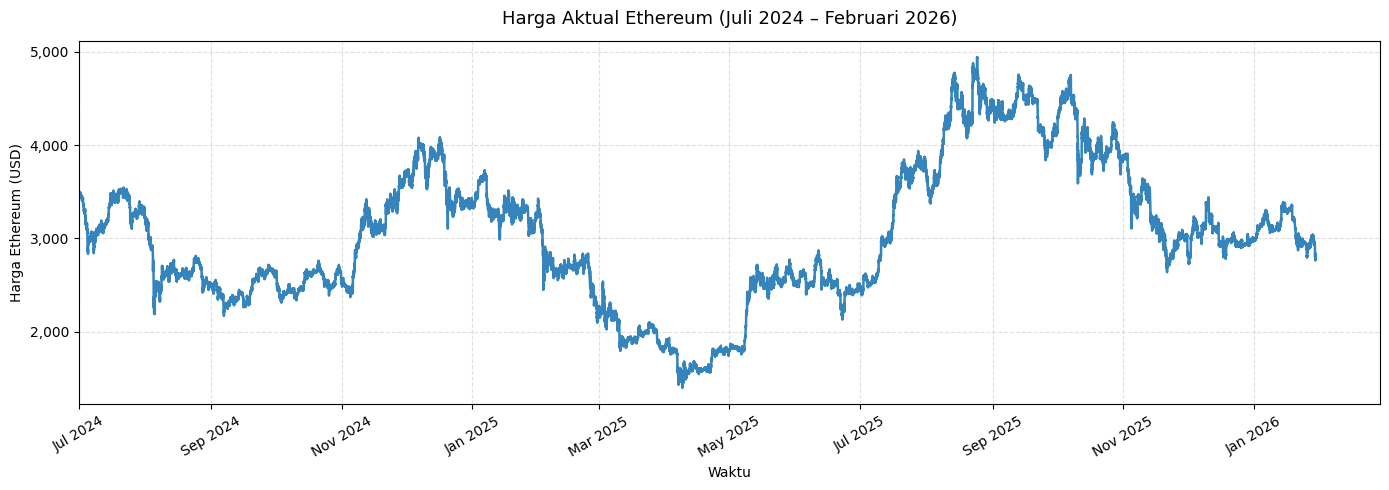

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator, FuncFormatter
import pandas as pd # Import pandas for Timestamp

# Define dates and actual for plotting
# The y_test (which is inversed to actual_price) corresponds to the data points starting from
# index 'window_size + train_size' in the original 'close_price' dataframe.
dates = close_price.index[window_size + train_size:]
actual = actual_price

# Define start_date and end_date for plotting limits
start_date = pd.Timestamp('2024-07-01')
end_date = pd.Timestamp('2026-02-28 23:59')

plt.figure(figsize=(14,5))

plt.plot(
    dates,
    actual,
    linewidth=1.8,
    alpha=0.9
)

plt.title(
    'Harga Aktual Ethereum (Juli 2024 – Februari 2026)',
    fontsize=13,
    pad=12
)
plt.xlabel('Waktu')
plt.ylabel('Harga Ethereum (USD)')


plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)   # ⬅️ tiap 2 bulan
)
plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter('%b %Y')     # Jul 2024
)
plt.xticks(rotation=30)


plt.gca().yaxis.set_major_locator(MultipleLocator(1000))
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{int(x):,}')
)


plt.xlim(start_date, end_date)
plt.grid(True, linestyle='--', alpha=0.4)
plt.margins(x=0.01)

plt.tight_layout()
plt.show()

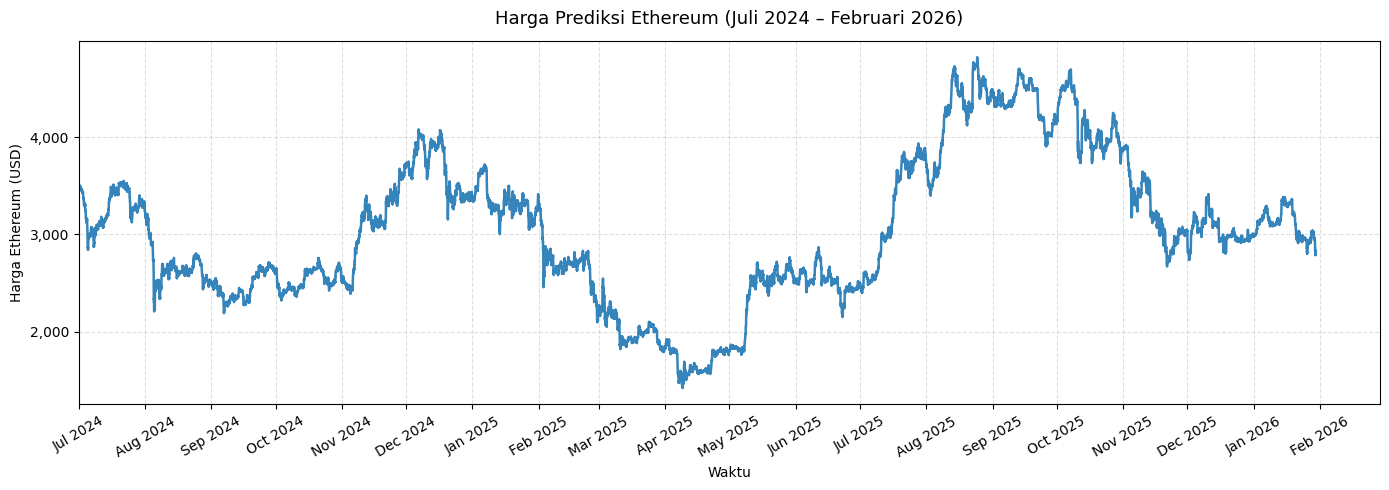

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator, FuncFormatter

# ===============================
# BATAS AKHIR: 28 FEBRUARI 2026
# ===============================
end_date = pd.Timestamp('2026-02-28 23:59')

plt.figure(figsize=(14,5))

# Fix: Assign predicted_price to predicted
predicted = predicted_price

plt.plot(
    dates,
    predicted,
    linestyle='-',
    linewidth=1.8,
    alpha=0.9
)

plt.title(
    'Harga Prediksi Ethereum (Juli 2024 – Februari 2026)',
    fontsize=13,
    pad=12
)
plt.xlabel('Waktu')
plt.ylabel('Harga Ethereum (USD)')

# =================================================
# FORMAT BULAN (PASTI ADA FEBRUARI)
# =================================================
# Major tick: setiap bulan (agar Feb muncul)
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())

# Format bulan
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

# Rotasi ringan
plt.xticks(rotation=30)

# ===============================
# FORMAT HARGA
# ===============================
plt.gca().yaxis.set_major_locator(MultipleLocator(1000))
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{int(x):,}')
)

# ===============================
# TAMPILAN BERSIH
# ===============================
plt.xlim(start_date, end_date)
plt.grid(True, linestyle='--', alpha=0.4)
plt.margins(x=0.01)

plt.tight_layout()
plt.show()

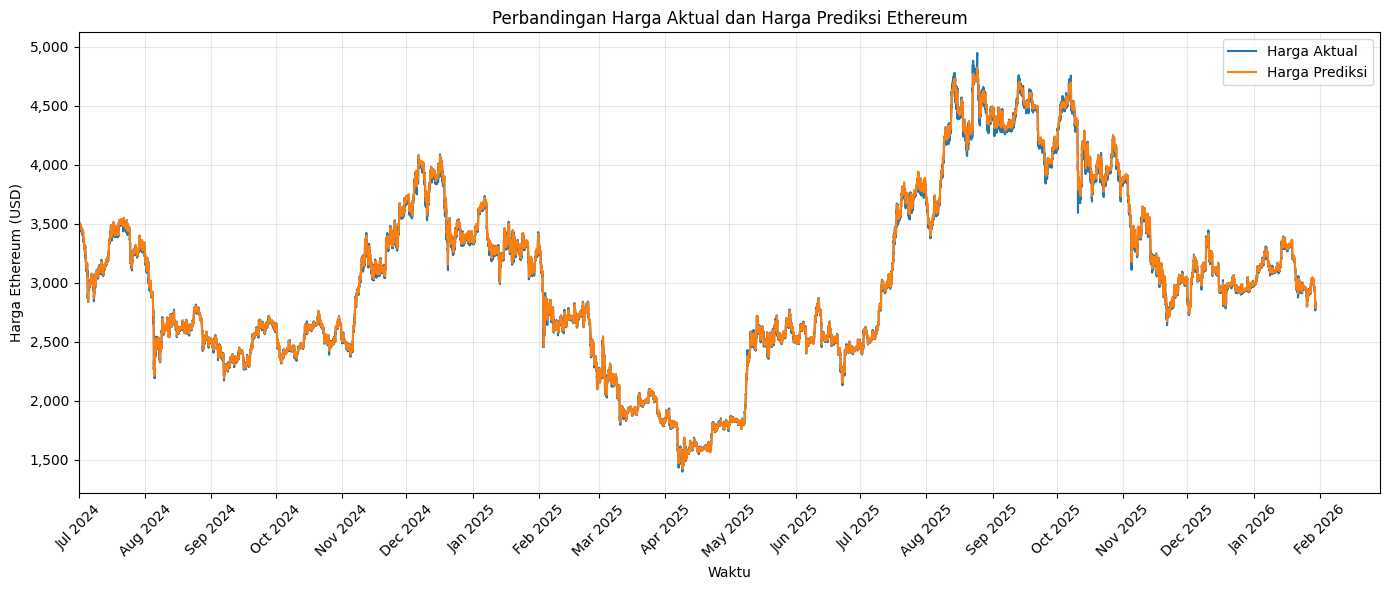

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# ===============================
# BATAS WAKTU
# ===============================
start_date = pd.Timestamp('2024-07-01')
end_date = pd.Timestamp('2026-02-28 23:59')

plt.figure(figsize=(14,6))

# -------------------------------
# GARIS HARGA AKTUAL
# -------------------------------
plt.plot(
    dates,
    actual,
    label='Harga Aktual',
    linewidth=1.5
)

# -------------------------------
# GARIS HARGA PREDIKSI
# -------------------------------
plt.plot(
    dates,
    predicted,
    label='Harga Prediksi',
    linewidth=1.5
)

plt.title('Perbandingan Harga Aktual dan Harga Prediksi Ethereum')
plt.xlabel('Waktu')
plt.ylabel('Harga Ethereum (USD)')

# ===============================
# FORMAT WAKTU (SEDERHANA)
# ===============================
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

# ===============================
# FORMAT HARGA
# ===============================
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{int(x):,}')
)

# ===============================
# GRID MIRIP CONTOH
# ===============================
plt.grid(True, which='both', linestyle='-', alpha=0.3)

# ===============================
# BATAS & LEGENDA
# ===============================
plt.xlim(start_date, end_date)
plt.legend()

plt.tight_layout()
plt.show()
